# **Optimizer (최적화 함수)**

Optimizer는 모델의 가중치(weight)를 업데이트하여 **손실(loss)**을 최소화하는 역할을 한다.

- `torch.optim` 안에 다양한 optimizer가 구현되어 있다.

## **1. 기본 학습 루프 구조**

Optimizer를 사용하는 학습 루프의 기본 구조는 다음과 같다.

```python
for epoch in range(num_epochs):
    y_pred = model(x)            # 1. forward
    loss = criterion(y_pred, y)  # 2. loss 계산
    optimizer.zero_grad()        # 3. 기울기 초기화
    loss.backward()              # 4. backward (기울기 계산)
    optimizer.step()             # 5. 파라미터 업데이트
```

| 단계 | 메서드 | 설명 |
|------|--------|------|
| 3 | `optimizer.zero_grad()` | `.grad`에 쌓인 기울기를 **0으로 초기화** |
| 4 | `loss.backward()` | 계산 그래프를 역방향으로 순회하며 **기울기 계산** |
| 5 | `optimizer.step()` | 계산된 기울기를 이용해 **파라미터 업데이트** |

## **2. 환경 설정**

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

## **3. SGD (Stochastic Gradient Descent)**

가장 기본적인 optimizer. 계산된 기울기 방향으로 파라미터를 조금씩 업데이트한다.

$$w \leftarrow w - \eta \cdot \nabla L(w)$$

- $\eta$ : 학습률 (learning rate)
- $\nabla L(w)$ : 손실 함수의 기울기

**Q1. XOR 문제를 SGD optimizer를 사용해 학습해보자.**

- 모델 : 입력 2 → 은닉층 4 → 출력 1 (활성화 함수: sigmoid)
- optimizer : `torch.optim.SGD`
- learning_rate : 1.0
- epoch : 10000

In [2]:
# 데이터 준비
X = torch.tensor([[0,0],[0,1],[1,0],[1,1]], dtype=torch.float32)
y = torch.tensor([[0],[1],[1],[0]], dtype=torch.float32)

In [3]:
# 모델 정의
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(2, 2)   # fc -> fully connected
        self.fc2 = nn.Linear(2, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        z1 = self.fc1(x)
        a1 = self.sigmoid(z1)
        z2 = self.fc2(a1)
        a2 = self.sigmoid(z2)
        return a2

In [4]:
# torch.optim._모델/알고리즘명_(model.parameters())
#                                   ^ 여기에 gradient 반영

In [5]:
# 모델, loss함수, optimizer 생성
model = MLP()
criterion = nn.BCELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1.0)

In [6]:
# 학습 루프
for epoch in range(1000):
    model.train()           #학습시에는 train
    # 1. forward
    y_pred = model(X)
    # 2. loss
    loss = criterion(y_pred, y)
    # 3. zero_grad
    optimizer.zero_grad()
    # 4. backward
    loss.backward()
    # 5. step
    optimizer.step()
    if epoch % 100 == 0:
        print(f'epoch {epoch:5d} | loss {loss.item():.4f}')

epoch     0 | loss 0.7072
epoch   100 | loss 0.6876
epoch   200 | loss 0.6237
epoch   300 | loss 0.4914
epoch   400 | loss 0.4165
epoch   500 | loss 0.3859
epoch   600 | loss 0.3724
epoch   700 | loss 0.3653
epoch   800 | loss 0.3611
epoch   900 | loss 0.3584


In [7]:
# 예측 결과 확인
import numpy as np
model.eval()        # 예측(검증시에는) model evaluation
with torch.no_grad():
    pred = model(X)
    print('예측값:', np.where(pred.T >= 0.5, 1, 0))
    print('정답  :', y.T)

예측값: [[0 0 1 1]]
정답  : tensor([[0., 1., 1., 0.]])


## **4. SGD + Momentum**

Momentum은 이전 이동 방향을 관성처럼 누적해 **진동을 줄이고 수렴 속도를 높인다.**

$$v_t = \mu v_{t-1} + \nabla L(w_t)$$
$$w_{t+1} = w_t - \eta\, v_t$$

- $\mu$ : momentum 계수 (보통 0.9)
- $v_t$ : 속도 (velocity)

**Q1. 위 모델을 momentum=0.9인 SGD로 다시 학습해보자.**

In [8]:
model_m = MLP()
criterion = nn.BCELoss()

# code here - optimizer 설정
optimizer_m = torch.optim.SGD(model_m.parameters(), lr=1.0, momentum=0.9)
model_m.train()
for epoch in range(10000):
    y_pred = model_m(X)
    loss = criterion(y_pred, y)
    optimizer_m.zero_grad()
    loss.backward()
    optimizer_m.step()

    if epoch % 1000 == 0:
        print(f'epoch {epoch:5d} | loss {loss.item():.4f}')

epoch     0 | loss 0.6968
epoch  1000 | loss 0.0010
epoch  2000 | loss 0.0005
epoch  3000 | loss 0.0003
epoch  4000 | loss 0.0002
epoch  5000 | loss 0.0002
epoch  6000 | loss 0.0002
epoch  7000 | loss 0.0001
epoch  8000 | loss 0.0001
epoch  9000 | loss 0.0001


In [9]:
# 예측 결과 확인
import numpy as np
model_m.eval()
with torch.no_grad():
    pred = model_m(X)
    print('예측값:', np.where(pred.T >= 0.5, 1, 0))
    print('정답  :', y.T)

예측값: [[0 1 1 0]]
정답  : tensor([[0., 1., 1., 0.]])


## **5. Adagrad**

파라미터마다 **학습률을 다르게 적용**한다. 자주 등장하는 파라미터는 학습률이 작아지고, 드물게 등장하는 파라미터는 학습률이 크게 유지된다.

$$s \leftarrow s + \left(\frac{\partial L}{\partial w}\right)^2$$
$$w \leftarrow w - \frac{\eta}{\sqrt{s}+\epsilon} \cdot \frac{\partial L}{\partial w}$$

- $s$ : 기울기 제곱의 누적 합
- $\epsilon$ : 0으로 나누는 것을 막는 아주 작은 수 (예: 1e-8)

**한계** : $s$가 계속 커지기만 하므로, 학습이 길어지면 실질적인 학습률이 0에 가까워진다.

**Q1. 위 모델을 Adagrad optimizer로 학습해보자.**

In [10]:
model_a = MLP()
criterion = nn.BCELoss()

# code here - optimizer 설정
optimizer_a = torch.optim.Adagrad(model_a.parameters(), lr = 1)

model_a.train()
for epoch in range(10000):
    y_pred = model_a(X)
    loss = criterion(y_pred, y)
    optimizer_a.zero_grad()
    loss.backward()
    optimizer_a.step()

    if epoch % 1000 == 0:
        print(f'epoch {epoch:5d} | loss {loss.item():.4f}')

epoch     0 | loss 0.7048
epoch  1000 | loss 0.4775
epoch  2000 | loss 0.4774
epoch  3000 | loss 0.4774
epoch  4000 | loss 0.4774
epoch  5000 | loss 0.4774
epoch  6000 | loss 0.4774
epoch  7000 | loss 0.4774
epoch  8000 | loss 0.4774
epoch  9000 | loss 0.4774


In [11]:
# 예측 결과 확인
import numpy as np
model.eval()
with torch.no_grad():
    pred = model_a(X)
    print('예측값:', np.where(pred.T > 0.5, 1, 0))
    print('정답  :', y.T)

예측값: [[0 1 1 1]]
정답  : tensor([[0., 1., 1., 0.]])


## **6. RMSProp**

Adagrad의 한계를 보완한다. 기울기 제곱을 단순 누적하지 않고 **지수이동평균**을 사용해 최근 기울기에 더 큰 가중치를 준다.

$$s \leftarrow \rho\, s + (1-\rho)\left(\frac{\partial L}{\partial w}\right)^2$$
$$w \leftarrow w - \frac{\eta}{\sqrt{s}+\epsilon} \cdot \frac{\partial L}{\partial w}$$

- $\rho$ : 감쇠율 (보통 0.9)

**Q1. RMSProp optimizer로 학습해보자. (lr=0.01, alpha=0.9)**

In [12]:
model_r = MLP()
criterion = nn.BCELoss()

# code here - optimizer 설정
optimizer_r = torch.optim.RMSprop(model_r.parameters(), lr = 0.1, alpha=0.9)

model_r.train()
for epoch in range(10000):
    y_pred = model_r(X)
    loss = criterion(y_pred, y)
    optimizer_r.zero_grad()
    loss.backward()
    optimizer_r.step()

    if epoch % 1000 == 0:
        print(f'epoch {epoch:5d} | loss {loss.item():.4f}')

epoch     0 | loss 0.6933
epoch  1000 | loss 0.0000
epoch  2000 | loss 0.0000
epoch  3000 | loss 0.0000
epoch  4000 | loss 0.0000
epoch  5000 | loss 0.0000
epoch  6000 | loss 0.0000
epoch  7000 | loss 0.0000
epoch  8000 | loss 0.0000
epoch  9000 | loss 0.0000


In [13]:
# 예측 결과 확인
import numpy as np
with torch.no_grad():
    pred = model_r(X)
    print('예측값:', np.where(pred.T > 0.5, 1, 0))
    print('정답  :', y.T)

예측값: [[0 1 1 0]]
정답  : tensor([[0., 1., 1., 0.]])


## **7. Adam**

현재 가장 널리 쓰이는 optimizer. **Momentum + RMSProp**을 결합한 방식이다.

$$m_t = \beta_1 m_{t-1} + (1-\beta_1)\,g_t \quad \text{(1차 모멘트 = 평균)}$$
$$v_t = \beta_2 v_{t-1} + (1-\beta_2)\,g_t^2 \quad \text{(2차 모멘트 = 분산)}$$
$$\hat{m}_t = \frac{m_t}{1-\beta_1^t}, \quad \hat{v}_t = \frac{v_t}{1-\beta_2^t} \quad \text{(편향 보정)}$$
$$w \leftarrow w - \frac{\eta}{\sqrt{\hat{v}_t}+\epsilon}\, \hat{m}_t$$

기본 파라미터: $\beta_1=0.9$, $\beta_2=0.999$, $\epsilon=10^{-8}$

**Q1. Adam optimizer로 학습해보자. (lr=0.01)**

In [ ]:
model_adam = MLP()
criterion = nn.BCELoss()

# code here - optimizer 설정
optimizer_adam = torch.optim.Adam(model_adam.parameters(), lr = 0.01, betas = (0.9, 0.999), eps = 1e-8)

for epoch in range(10000):
    y_pred = model_adam(X)
    loss = criterion(y_pred, y)
    optimizer_adam.zero_grad()
    loss.backward()
    optimizer_adam.step()

    if epoch % 1000 == 0:
        print(f'epoch {epoch:5d} | loss {loss.item():.4f}')

epoch     0 | loss 0.7120
epoch  1000 | loss 0.0315
epoch  2000 | loss 0.0083
epoch  3000 | loss 0.0036
epoch  4000 | loss 0.0018
epoch  5000 | loss 0.0010
epoch  6000 | loss 0.0006
epoch  7000 | loss 0.0003
epoch  8000 | loss 0.0002
epoch  9000 | loss 0.0001


In [27]:
# 예측 결과 확인
import numpy as np
with torch.no_grad():
    pred = model_adam(X)
    print('예측값:', np.where(pred.T >= 0.5, 1, 0))
    print('정답  :', y.T)

예측값: [[0 1 1 0]]
정답  : tensor([[0., 1., 1., 0.]])


## **8. Optimizer 비교**

**Q1. 5가지 optimizer (SGD, SGD+Momentum, Adagrad, RMSProp, Adam)를 같은 초기 가중치에서 시작해 loss 수렴 속도를 비교해보자.**

힌트: `torch.manual_seed(42)`로 초기 가중치를 고정한다.

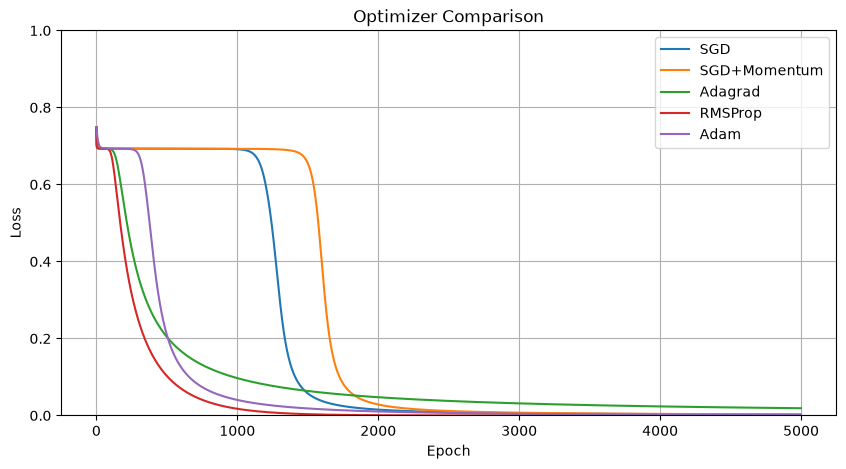

In [16]:
import matplotlib.pyplot as plt

def train(optimizer_name, lr, epochs=5000, **kwargs):
    torch.manual_seed(42)
    model = MLP()
    criterion = nn.BCELoss()

    # TODO: optimizer_name 에 따라 알맞은 optimizer를 생성하세요
    optimizer = {
      'SGD':      torch.optim.SGD(model.parameters(), lr=lr, **kwargs),
      'Adagrad':  torch.optim.Adagrad(model.parameters(), lr=lr),
      'RMSProp':  torch.optim.RMSprop(model.parameters(), lr=lr),
      'Adam':     torch.optim.Adam(model.parameters(), lr=lr),
    }[optimizer_name]

    losses = []
    for epoch in range(epochs):
        y_pred = model(X)
        loss = criterion(y_pred, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    return losses

# 각 optimizer 학습
results = {
    'SGD':           train('SGD', lr=1.0),
    'SGD+Momentum':  train('SGD', lr=0.1, momentum=0.9),
    'Adagrad':       train('Adagrad', lr=0.1),
    'RMSProp':       train('RMSProp', lr=0.01),
    'Adam':          train('Adam', lr=0.01),
}

# 그래프 출력
plt.figure(figsize=(10, 5))
for name, losses in results.items():
    plt.plot(losses, label=name)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Optimizer Comparison')
plt.legend()
plt.ylim(0, 1)
plt.grid(True)
plt.show()